In [1]:
from google.colab import files

uploaded = files.upload()

Saving archive (3).zip to archive (3).zip


In [2]:
import zipfile
import os

zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/weather_data')

print("Dataset extracted successfully!")
print(os.listdir('/content/weather_data'))

Dataset extracted successfully!
['weatherHistory.csv']


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout

In [4]:
file_path = '/content/weather_data/weatherHistory.csv'

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (96453, 12)


In [5]:
df.head(10)

,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,Partly cloudy throughout the day.
1,2006-04-01 01:00:00.000 +0200,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,0.0,1015.63,Partly cloudy throughout the day.
2,2006-04-01 02:00:00.000 +0200,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204.0,14.9569,0.0,1015.94,Partly cloudy throughout the day.
3,2006-04-01 03:00:00.000 +0200,Partly Cloudy,rain,8.288889,5.944444,0.83,14.1036,269.0,15.8263,0.0,1016.41,Partly cloudy throughout the day.
4,2006-04-01 04:00:00.000 +0200,Mostly Cloudy,rain,8.755556,6.977778,0.83,11.0446,259.0,15.8263,0.0,1016.51,Partly cloudy throughout the day.
5,2006-04-01 05:00:00.000 +0200,Partly Cloudy,rain,9.222222,7.111111,0.85,13.9587,258.0,14.9569,0.0,1016.66,Partly cloudy throughout the day.
6,2006-04-01 06:00:00.000 +0200,Partly Cloudy,rain,7.733333,5.522222,0.95,12.3648,259.0,9.9820,0.0,1016.72,Partly cloudy throughout the day.
7,2006-04-01 07:00:00.000 +0200,Partly Cloudy,rain,8.772222,6.527778,0.89,14.1519,260.0,9.9820,0.0,1016.84,Partly cloudy throughout the day.
8,2006-04-01 08:00:00.000 +0200,Partly Cloudy,rain,10.822222,10.822222,0.82,11.3183,259.0,9.9820,0.0,1017.37,Partly cloudy throughout the day.
9,2006-04-01 09:00:00.000 +0200,Partly Cloudy,rain,13.772222,13.772222,0.72,12.5258,279.0,9.9820,0.0,1017.22,Partly cloudy throughout the day.


In [6]:
print(df.columns.tolist())

['Formatted Date', 'Summary', 'Precip Type', 'Temperature (C)', 'Apparent Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 'Wind Bearing (degrees)', 'Visibility (km)', 'Loud Cover', 'Pressure (millibars)', 'Daily Summary']


In [7]:
df['Formatted Date'] = pd.to_datetime(df['Formatted Date'],utc=True)

df = df.sort_values('Formatted Date')

print(df[['Formatted Date', 'Temperature (C)']].head())

                Formatted Date  Temperature (C)
2880 2005-12-31 23:00:00+00:00         0.577778
2881 2006-01-01 00:00:00+00:00         1.161111
2882 2006-01-01 01:00:00+00:00         1.666667
2883 2006-01-01 02:00:00+00:00         1.711111
2884 2006-01-01 03:00:00+00:00         1.183333


In [8]:
print(df.isnull().sum())

Formatted Date                0
Summary                       0
Precip Type                 517
Temperature (C)               0
Apparent Temperature (C)      0
Humidity                      0
Wind Speed (km/h)             0
Wind Bearing (degrees)        0
Visibility (km)               0
Loud Cover                    0
Pressure (millibars)          0
Daily Summary                 0
dtype: int64


In [9]:
features = ['Temperature (C)','Humidity','Wind Speed (km/h)']

df[features] = df[features].interpolate()

df[features] = df[features].ffill()
df[features] = df[features].bfill()

print("Missing values after handling:")
print(df[features].isnull().sum())

Missing values after handling:
Temperature (C)      0
Humidity             0
Wind Speed (km/h)    0
dtype: int64


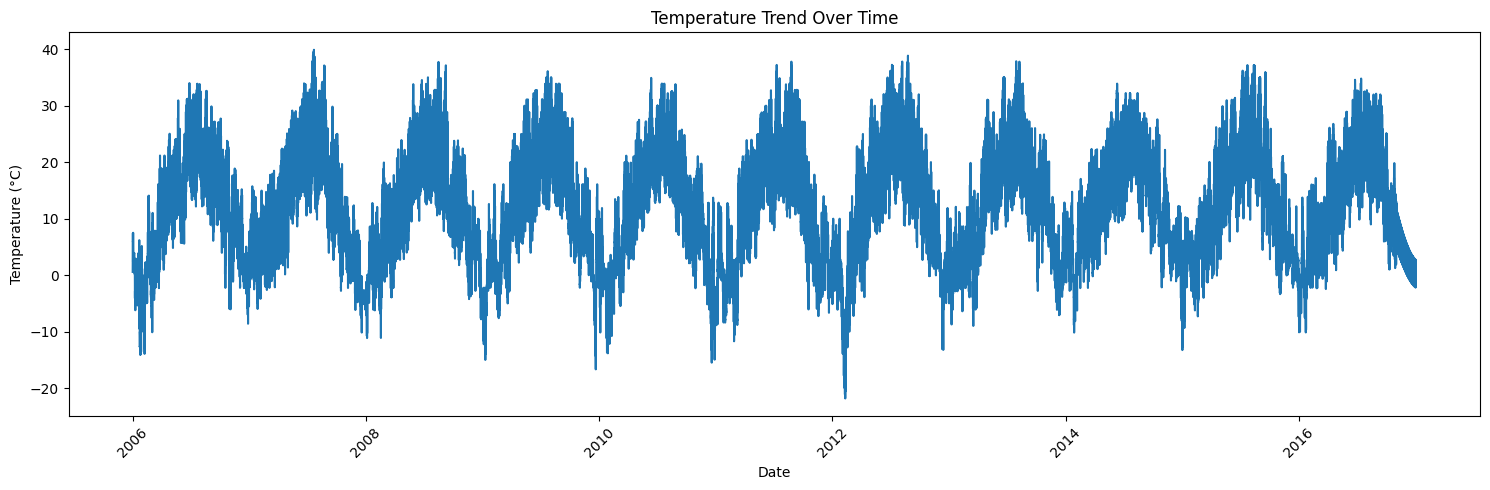

In [10]:
plt.figure(figsize=(15, 5))

plt.plot(df['Formatted Date'],df['Temperature (C)'])

plt.title('Temperature Trend Over Time')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
data = df[features].copy()

data.head()

,Temperature (C),Humidity,Wind Speed (km/h)
2880,0.577778,0.89,17.1143
2881,1.161111,0.85,16.6152
2882,1.666667,0.82,20.2538
2883,1.711111,0.82,14.4900
2884,1.183333,0.86,13.9426


In [12]:
scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(data)

print("Scaled data shape:", scaled_data.shape)
print(scaled_data[:5])

Scaled data shape: (96453, 3)
[[0.36288363 0.89       0.26802824]
 [0.37233372 0.85       0.2602118 ]
 [0.38052381 0.82       0.31719617]
 [0.38124381 0.82       0.2269289 ]
 [0.37269373 0.86       0.21835603]]


In [13]:
sequence_length = 7

X = []
y = []

for i in range(sequence_length, len(scaled_data)):

    X.append(scaled_data[i-sequence_length:i])

    y.append(scaled_data[i, 0])

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (96446, 7, 3)
y shape: (96446,)


In [14]:
n = len(X)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train = X[:train_end]
y_train = y[:train_end]

X_val = X[train_end:val_end]
y_val = y[train_end:val_end]

X_test = X[val_end:]
y_test = y[val_end:]

print("Training data:", X_train.shape, y_train.shape)
print("Validation data:", X_val.shape, y_val.shape)
print("Testing data:", X_test.shape, y_test.shape)

Training data: (67512, 7, 3) (67512,)
Validation data: (14467, 7, 3) (14467,)
Testing data: (14467, 7, 3) (14467,)


In [15]:
model = Sequential()

model.add(SimpleRNN(64,input_shape=(X_train.shape[1], X_train.shape[2])))

model.add(Dropout(0.2))

model.add(Dense(1))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,417 (17.25 KB)

 Trainable params: 4,417 (17.25 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
model.compile(optimizer='adam',loss='mse',metrics=['mae'])

print("Model compiled successfully!")

Model compiled successfully!


In [17]:
history = model.fit(X_train,y_train,validation_data=(X_val, y_val),epochs=50,batch_size=32,verbose=1)

Epoch 1/50
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - loss: 0.0035 - mae: 0.0426 - val_loss: 4.1931e-04 - val_mae: 0.0156
Epoch 2/50
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - loss: 0.0012 - mae: 0.0267 - val_loss: 3.1034e-04 - val_mae: 0.0129
Epoch 3/50
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - loss: 8.3538e-04 - mae: 0.0217 - val_loss: 2.8612e-04 - val_mae: 0.0125
Epoch 4/50
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 6.8387e-04 - mae: 0.0194 - val_loss: 3.1214e-04 - val_mae: 0.0127
Epoch 5/50
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - loss: 6.2698e-04 - mae: 0.0184 - val_loss: 2.8263e-04 - val_mae: 0.0120
Epoch 6/50
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - loss: 6.1028e-04 - mae: 0.0181 - val_loss: 2.7511e-04 - val_mae: 0.0123
Epoch 7/50
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - loss: 5.9641e-04 - mae: 0.0179 - val_loss: 3.0199e-04 - val_mae: 0.0136
Epoch 8/50
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 5.9285e-04 - mae: 0.0178 - val_loss: 2.9051e-04

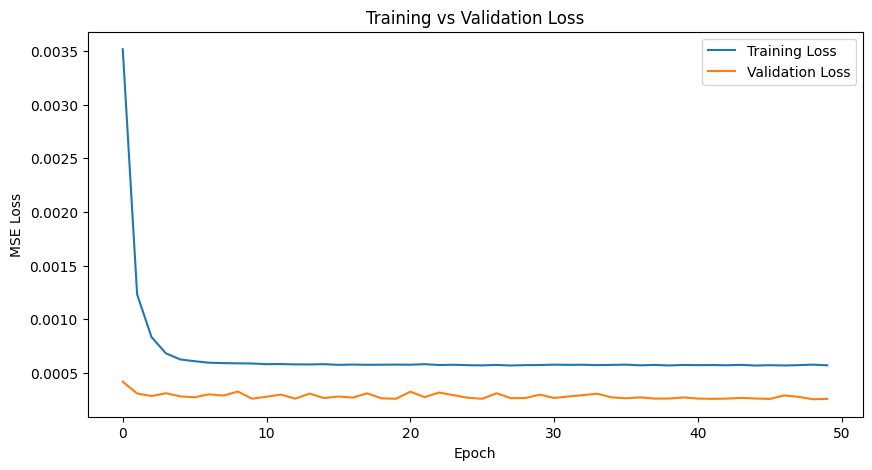

In [18]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'],label='Training Loss')

plt.plot(history.history['val_loss'],label='Validation Loss')

plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')

plt.legend()
plt.show()

In [19]:
y_pred_scaled = model.predict(X_test)

print("Prediction completed!")

453/453 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Prediction completed!


In [20]:
temperature_min = scaler.data_min_[0]
temperature_max = scaler.data_max_[0]

y_test_actual = (y_test * (temperature_max - temperature_min)+ temperature_min)

y_pred_actual = (y_pred_scaled.flatten()* (temperature_max - temperature_min)+ temperature_min)

print("Actual temperatures:")
print(y_test_actual[:5])

print("\nPredicted temperatures:")
print(y_pred_actual[:5])

Actual temperatures:
[ 9.84444444 13.66666667 16.92222222 18.83888889 21.08333333]

Predicted temperatures:
[ 8.21145401  9.97067671 14.61278352 18.32026572 19.81645244]


In [21]:
rmse = np.sqrt(mean_squared_error(y_test_actual,y_pred_actual))

mae = mean_absolute_error(y_test_actual,y_pred_actual)

r2 = r2_score(y_test_actual,y_pred_actual)

print("Model Evaluation Results")
print("-----------------------------")
print("RMSE:", rmse)
print("MAE :", mae)
print("R²  :", r2)

Model Evaluation Results
-----------------------------
RMSE: 0.9980410449554187
MAE : 0.7210928017368888
R²  : 0.9883401023113131


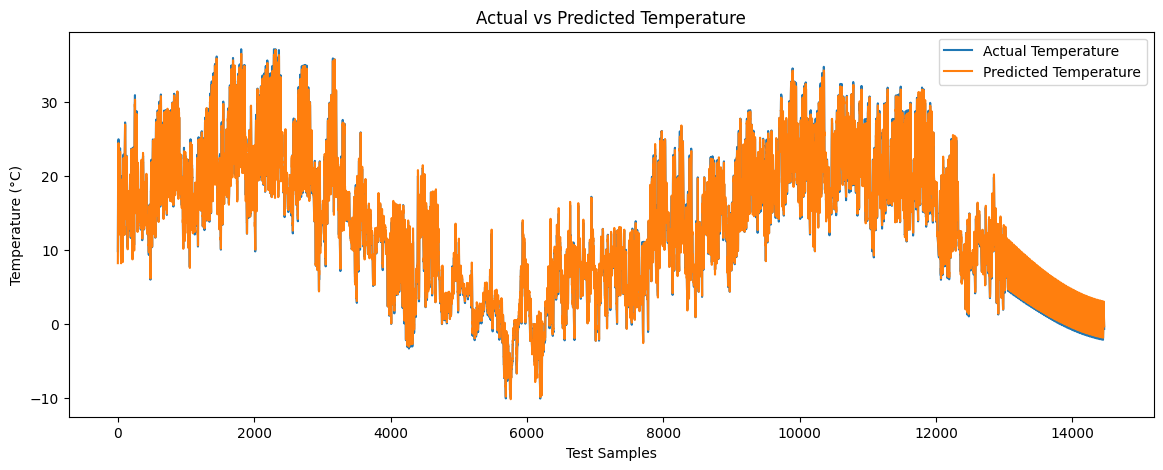

In [22]:
plt.figure(figsize=(14, 5))

plt.plot(y_test_actual,label='Actual Temperature')

plt.plot(y_pred_actual,label='Predicted Temperature')

plt.title('Actual vs Predicted Temperature')
plt.xlabel('Test Samples')
plt.ylabel('Temperature (°C)')

plt.legend()
plt.show()

In [23]:
last_sequence = scaled_data[-sequence_length:].copy()

future_predictions_scaled = []

print("Last 7 days prepared!")

Last 7 days prepared!


In [24]:
for i in range(7):

    current_input = last_sequence.reshape(1,sequence_length,len(features))

    next_prediction = model.predict(current_input,verbose=0)[0, 0]

    future_predictions_scaled.append(next_prediction)

    next_day_features = np.array([next_prediction,last_sequence[-1, 1],last_sequence[-1, 2]])

    last_sequence = np.vstack([last_sequence[1:],next_day_features])

print("7-day prediction completed!")

7-day prediction completed!


In [25]:
future_predictions_scaled = np.array(future_predictions_scaled)

future_temperatures = (future_predictions_scaled* (temperature_max - temperature_min)+ temperature_min)

print("Predicted temperatures for next 7 days:")
print(future_temperatures)

Predicted temperatures for next 7 days:
[-0.49210763 -0.20647914  0.15997354  0.5956589   1.06840731  1.57204865
  2.08049694]


In [26]:
last_date = df['Formatted Date'].iloc[-1]

future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1),periods=7)

forecast_df = pd.DataFrame({'Date': future_dates,'Predicted Temperature (°C)': future_temperatures})

forecast_df

,Date,Predicted Temperature (°C)
0,2017-01-01 22:00:00+00:00,-0.492108
1,2017-01-02 22:00:00+00:00,-0.206479
2,2017-01-03 22:00:00+00:00,0.159974
3,2017-01-04 22:00:00+00:00,0.595659
4,2017-01-05 22:00:00+00:00,1.068407
5,2017-01-06 22:00:00+00:00,1.572049
6,2017-01-07 22:00:00+00:00,2.080497


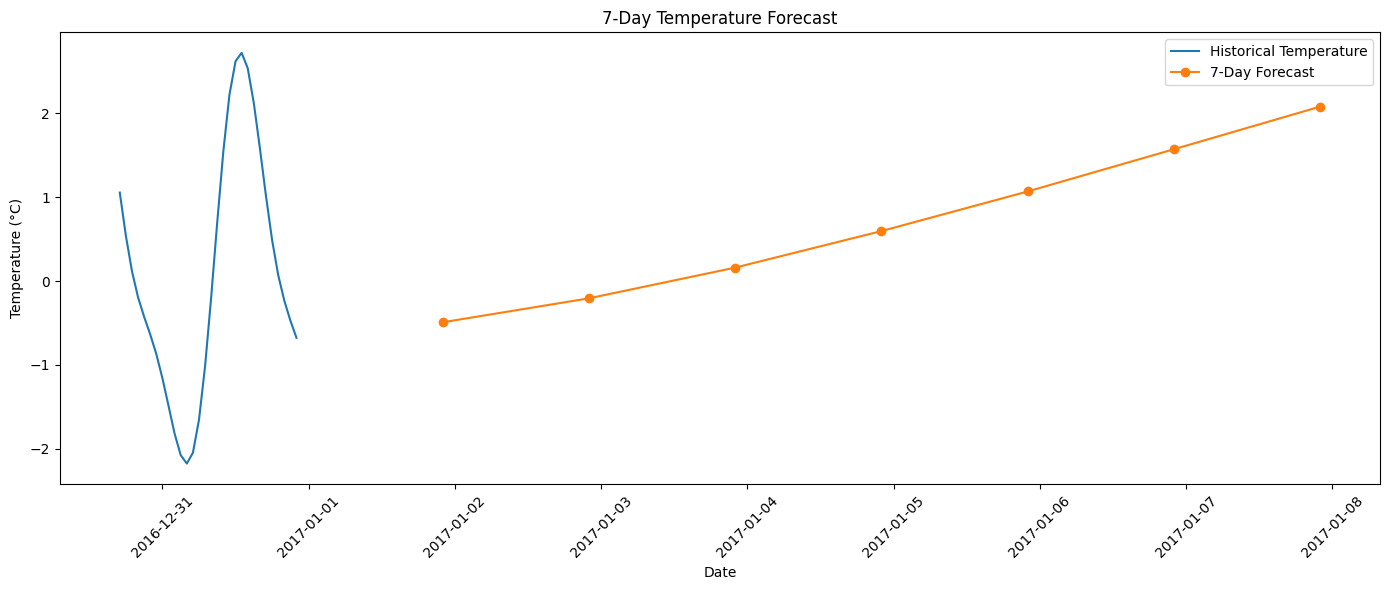

In [27]:
recent_days = 30

recent_data = df.tail(recent_days)

plt.figure(figsize=(14, 6))

plt.plot(recent_data['Formatted Date'],recent_data['Temperature (C)'],label='Historical Temperature')

plt.plot(forecast_df['Date'],forecast_df['Predicted Temperature (°C)'],marker='o',label='7-Day Forecast')

plt.title('7-Day Temperature Forecast')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')

plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.show()

In [28]:
forecast_df.to_csv('7_day_temperature_forecast.csv',index=False)

print("Forecast saved successfully!")

Forecast saved successfully!
